In [1]:
1250080036%25

11

In [28]:
%pip install mlxtend openpyxl

Note: you may need to restart the kernel to use updated packages.


# Lab01: Regression
##  1.1 Linear Regression
### Khai báo sử dụng thư viện

In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder , PolynomialFeatures
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from mlxtend.plotting import  scatterplotmatrix , heatmap
import seaborn as sns
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score 
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor , AdaBoostRegressor ,HistGradientBoostingRegressor

In [ ]:
df = pd.read_excel('Banking.xlsx')
df.head()

In [63]:
cols = ['gender', 'Amountinvestedmonthly', 'Credit score']
df = pd.read_excel('Banking.xlsx', usecols = cols )
df.head()

,gender,Credit score,Amountinvestedmonthly
0,Female,833.0,236.642680
1,Female,833.0,39.684018
2,Male,833.0,397.503650
3,Male,833.0,69.107006
4,Female,833.0,59.366058


# 1.2 preprocessing

In [64]:
encoder = LabelEncoder()
df['gender'] = encoder.fit_transform(df['gender'])

In [65]:
df.head()

,gender,Credit score,Amountinvestedmonthly
0,0,833.0,236.642680
1,0,833.0,39.684018
2,1,833.0,397.503650
3,1,833.0,69.107006
4,0,833.0,59.366058


In [66]:
df.isna().sum()

gender                     0
Credit score               4
Amountinvestedmonthly    331
dtype: int64

In [67]:
df.dropna(axis = 0 , inplace = True)

In [68]:
df.isna().sum()

gender                   0
Credit score             0
Amountinvestedmonthly    0
dtype: int64

# 1.3 Correlation (Hệ số tương quan)

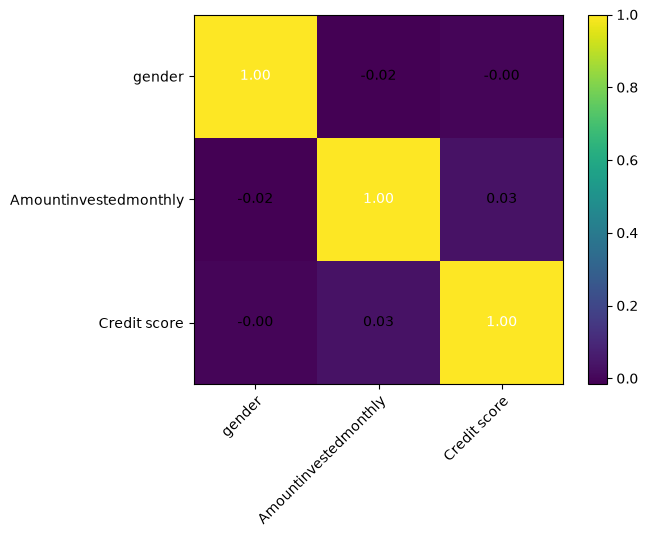

In [69]:
cols_con = ['gender', 'Amountinvestedmonthly', 'Credit score']
heatmap(df[cols_con].corr().values, row_names=cols_con, column_names=cols_con)
plt.show()

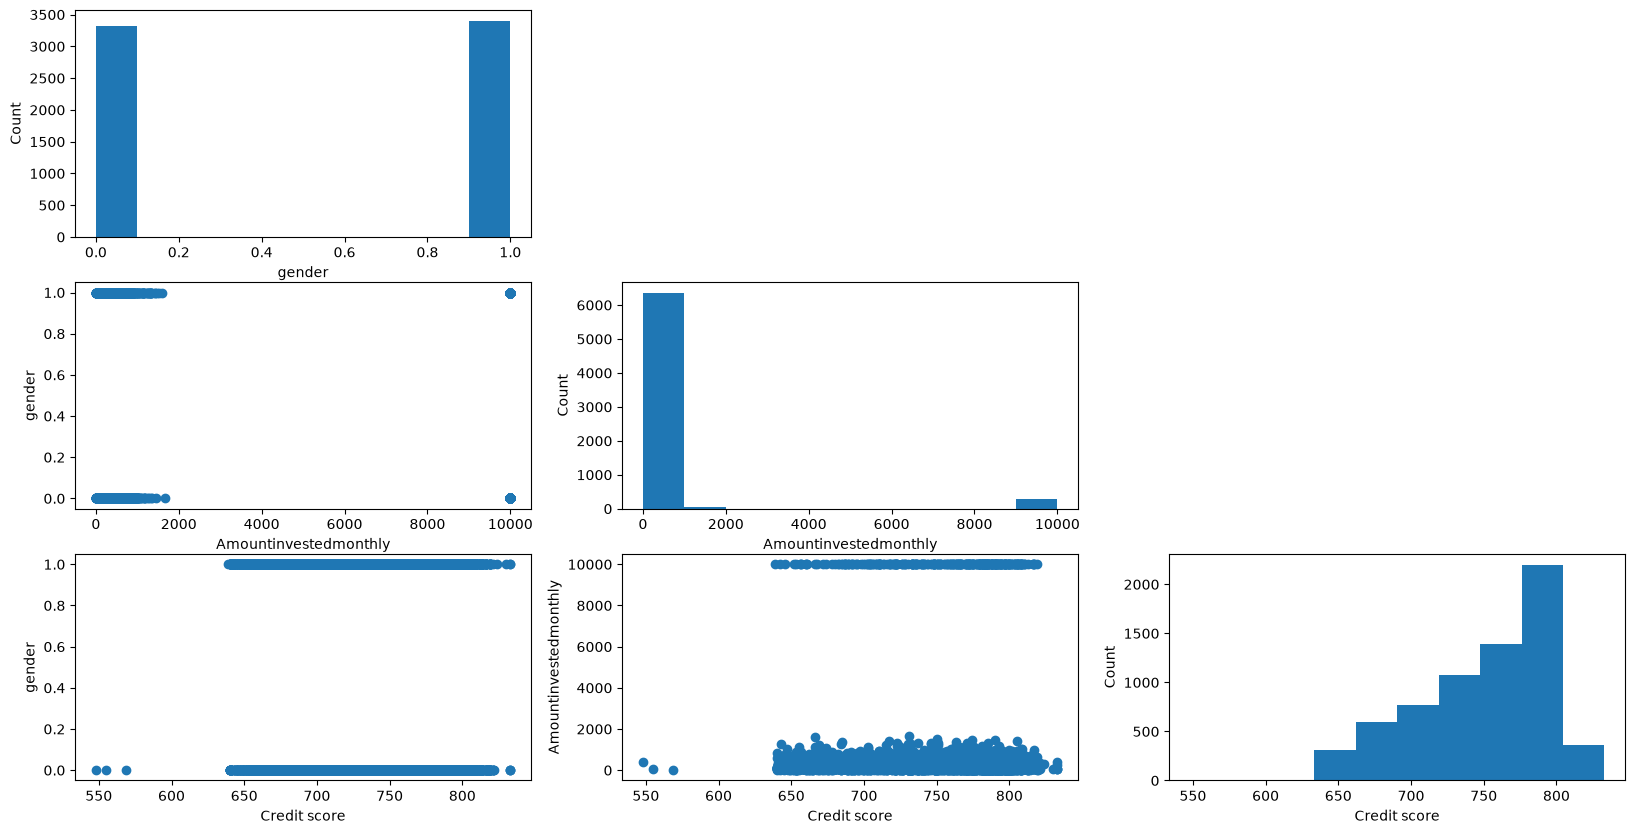

In [70]:
scatterplotmatrix(df[cols_con].values, names = cols_con , figsize=(20 ,10) )
plt.show()

# 1.4 Build model


In [71]:
X = df.drop(columns = 'Credit score')
y = df['Credit score']
X_train,X_test , y_train , y_test = train_test_split(X,y)
X_train.shape ,X_test.shape , y_train.shape , y_test.shape 


((5031, 2), (1677, 2), (5031,), (1677,))

In [72]:
lg = LinearRegression()
lg.fit(X_train ,y_train)
lg.score(X_train ,y_train) , lg.score(X_test ,y_test)

(0.0007546270852870629, 0.0010807605606675263)

# 1.5 Feature importances

In [73]:
df_imp = pd.DataFrame({
    'importances':lg.coef_,
    'features':lg.feature_names_in_
}).sort_values(by='importances')
df_imp

,importances,features
1,0.000565,Amountinvestedmonthly
0,0.897372,gender


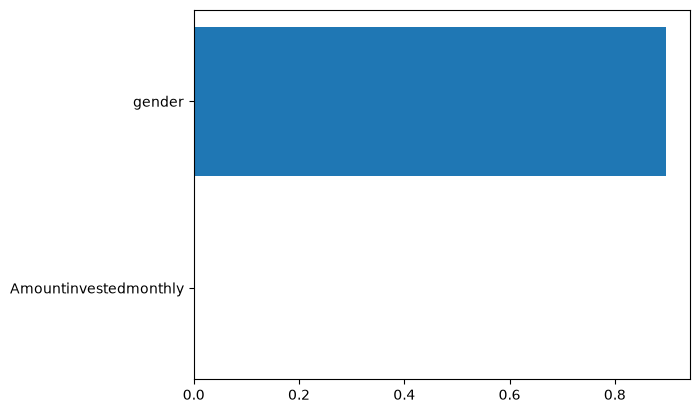

In [74]:
plt.barh(y=df_imp['features'], width=df_imp['importances'])
plt.show()

# Linear Regression with Polynomial

In [75]:
pf = PolynomialFeatures(degree=2)
X_train_pf = pf.fit_transform(X_train)
X_test_pf = pf.transform(X_test)

In [76]:
lg = LinearRegression()
lg.fit(X_train_pf ,y_train)
lg.score(X_train_pf ,y_train) , lg.score(X_test_pf ,y_test)

(0.001178249189286551, 0.00013941513358728397)

In [77]:
dt = DecisionTreeRegressor()
dt.fit(X_train ,y_train)
dt.score(X_train ,y_train) , dt.score(X_test ,y_test)

(0.9571325965132605, -0.8812467104190902)

In [78]:
grid = GridSearchCV(estimator=dt,param_grid={
    'max_depth':[5,6,7],
    'min_samples_split':[2,3,4],
    'min_samples_leaf':[1,2,3,4]
})
grid.fit(X_train,y_train)
grid.best_score_,grid.best_params_

(np.float64(-0.01951612235405644),
 {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2})

In [79]:
dt = DecisionTreeRegressor(**grid.best_params_)
dt.fit(X_train ,y_train)
dt.score(X_train ,y_train) , dt.score(X_test ,y_test)

(0.014745347570753298, -0.03205943030636704)

In [80]:
rf = RandomForestRegressor()
rf.fit(X_train ,y_train)
rf.score(X_train ,y_train) , rf.score(X_test ,y_test)

(0.7700811199674844, -0.29715896476698056)

In [81]:
grid = GridSearchCV(estimator=rf,param_grid={
    'max_depth':[7,8,9],
    'min_samples_split':[2,3],
    'min_samples_leaf':[1,2,3,4]
})
grid.fit(X_train,y_train)
grid.best_score_,grid.best_params_

(np.float64(-0.009382187342045545),
 {'max_depth': 7, 'min_samples_leaf': 3, 'min_samples_split': 3})

In [82]:
rf = RandomForestRegressor(**grid.best_params_)
rf.fit(X_train ,y_train)
rf.score(X_train ,y_train) , rf.score(X_test ,y_test)

(0.05333242433308305, -0.007029920550507107)

In [83]:
adaboost = AdaBoostRegressor()
adaboost.fit(X_train ,y_train)
adaboost.score(X_train ,y_train) , adaboost.score(X_test ,y_test)

(-0.14135224335973362, -0.1382316103336747)

In [84]:
hist = HistGradientBoostingRegressor()
hist.fit(X_train ,y_train)
hist.score(X_train ,y_train) , hist.score(X_test ,y_test)

(0.061928099477759124, -0.023459119190346378)

In [85]:
df_imp = pd.DataFrame({
    'features': rf.feature_names_in_,
    'importances':rf.feature_importances_
}).sort_values(by='importances')
df_imp

,features,importances
0,gender,0.054123
1,Amountinvestedmonthly,0.945877


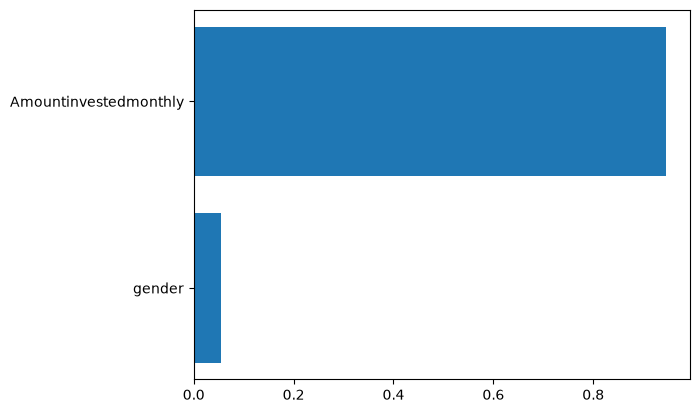

In [86]:
plt.barh(y = df_imp['features'], width= df_imp['importances'])
plt.show()

# 1.6 Validation


In [87]:
y_test_pred = rf.predict(X_test)
data_validation = []
data_validation.append({
    'model':'RandomForest',
    'mean_absolute_error': mean_absolute_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
y_test_pred = dt.predict(X_test)
data_validation.append({
    'model':'DecisionTree',
    'mean_absolute_error': mean_absolute_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
y_test_pred = adaboost.predict(X_test)
data_validation.append({
    'model':'AdaBoost',
    'mean_absolute_error': mean_absolute_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
y_test_pred = hist.predict(X_test)
data_validation.append({
    'model':'HistGradientBoosting',
    'mean_absolute_error': mean_absolute_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
df_validation = pd.DataFrame(data_validation)
df_validation

,model,mean_absolute_error,mean_squared_error
0,RandomForest,38.948826,2096.408883
1,DecisionTree,39.260244,2148.514670
2,AdaBoost,42.691416,2369.541172
3,HistGradientBoosting,39.014268,2130.610764
